Open in Colab if you do not see the 2 rendered animation video examples at the bottom of this notebook: https://colab.research.google.com/drive/14JgmuF8cVcVFUDuewMBs5dbpcYOdK7GR

# SkillCorner Body Pose Visualization Example

This notebook demonstrates some examples of using the visualizer code located here: https://github.com/MattLowrieDS/skillcorner_pose_viz

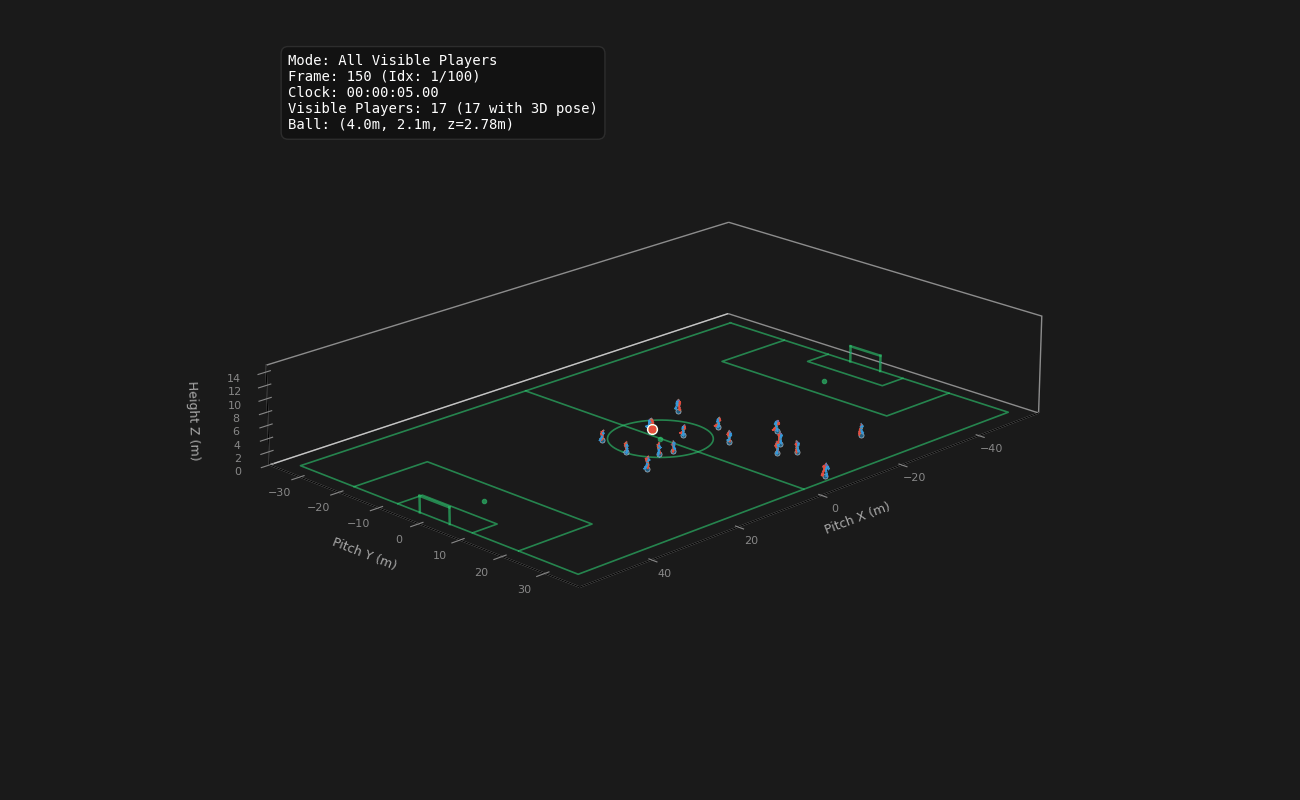

In [17]:
# You will need to add a Hugging Face auth token with the name HF_TOKEN
# in the "Secrets" section of the Colab sidebar options
!hf update && hf download SkillCorner/opendata-bodypose --repo-type dataset --local-dir .

In [18]:
!git clone https://github.com/SkillCorner/opendata.git
!git clone https://github.com/MattLowrieDS/skillcorner_pose_viz.git

In [19]:
!cd raw && unzip -o 1925299.jsonl.zip
!cd raw && unzip -o 1996435.jsonl.zip

In [12]:
import sys
sys.path.append('/content/skillcorner_pose_viz')

import polars as pl
import matplotlib.pyplot as plt
from IPython.display import Image, display
import skillcorner_pose_viz.animate as bpviz
from opendata.src.data import pose_loading
from IPython.display import HTML

# Print a list of all shot events and pick one to animate

In [13]:
# Find all shot events from match
match_id = 1925299

# Brisbane Roar v Perth Glory, 2024-12-21
dynev_df = pl.read_csv(f'opendata/data/matches/{match_id}/{match_id}_dynamic_events.csv')

shots_df = (dynev_df.filter(
    pl.col('event_type') == 'player_possession',
    pl.col('end_type') == 'shot',
).with_row_index(name='shot_id', offset=0))

# Print a table with all shot events
with pl.Config(tbl_rows=-1, tbl_cols=-1):
  print(shots_df['shot_id', 'period', 'time_start', 'time_end', 'frame_start', 'frame_end', 'player_id'])

shape: (30, 7)
┌─────────┬────────┬────────────┬──────────┬─────────────┬───────────┬───────────┐
│ shot_id ┆ period ┆ time_start ┆ time_end ┆ frame_start ┆ frame_end ┆ player_id │
│ ---     ┆ ---    ┆ ---        ┆ ---      ┆ ---         ┆ ---       ┆ ---       │
│ u32     ┆ i64    ┆ str        ┆ str      ┆ i64         ┆ i64       ┆ i64       │
╞═════════╪════════╪════════════╪══════════╪═════════════╪═══════════╪═══════════╡
│ 0       ┆ 1      ┆ 05:55.6    ┆ 05:55.6  ┆ 3566        ┆ 3566      ┆ 560882    │
│ 1       ┆ 1      ┆ 09:23.8    ┆ 09:24.9  ┆ 5648        ┆ 5659      ┆ 966112    │
│ 2       ┆ 1      ┆ 18:34.9    ┆ 18:36.2  ┆ 11159       ┆ 11172     ┆ 966114    │
│ 3       ┆ 1      ┆ 22:48.6    ┆ 22:48.6  ┆ 13696       ┆ 13696     ┆ 560989    │
│ 4       ┆ 1      ┆ 24:36.1    ┆ 24:37.2  ┆ 14771       ┆ 14782     ┆ 797298    │
│ 5       ┆ 1      ┆ 26:20.7    ┆ 26:21.9  ┆ 15817       ┆ 15829     ┆ 966112    │
│ 6       ┆ 1      ┆ 26:31.0    ┆ 26:31.7  ┆ 15920       ┆ 15927     ┆ 5

# Animate the shot event

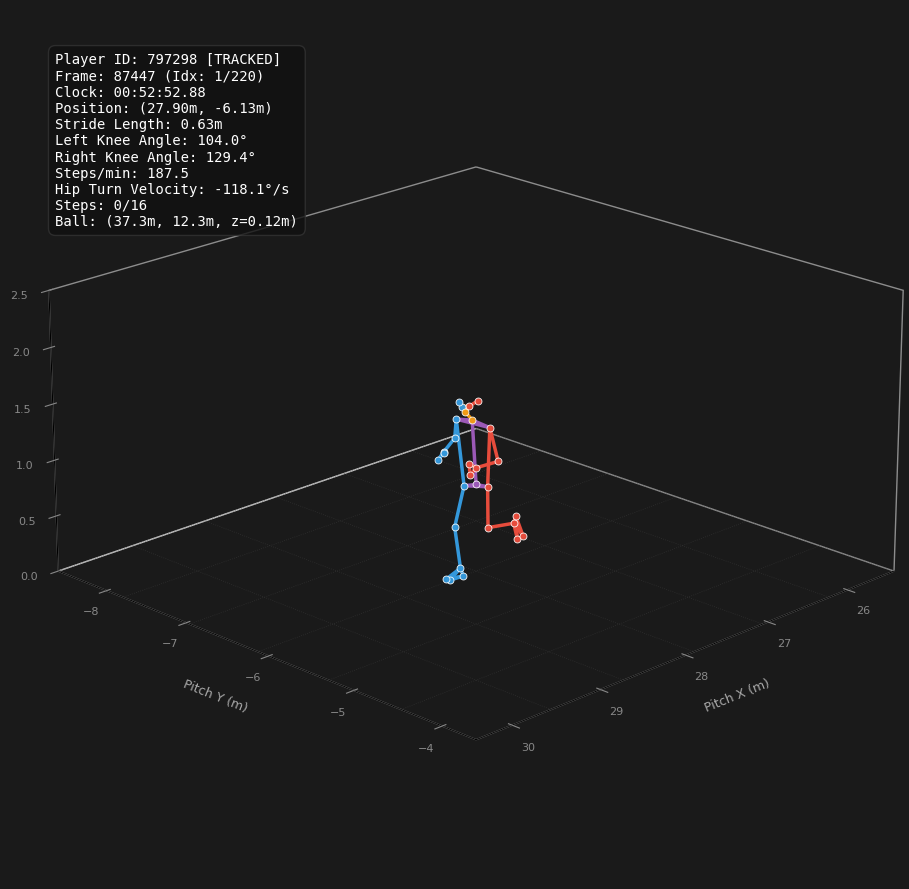

In [14]:
# Animate one of the players taking a (missed) shot during the match
shot_id = 14

frame_padding = 110
track_frame_id = shots_df['frame_start'][shot_id]
pose_frame_id = int(pose_loading.tracking_to_pose_frame(track_frame_id))
player_id = shots_df['player_id'][shot_id]

anim = bpviz.animate_soccer_pose(
    path_to_jsonl=f'/content/raw/{match_id}.jsonl',
    start_frame=pose_frame_id - frame_padding,
    num_frames=frame_padding * 2,
    player_id=player_id,
)
HTML(anim.to_html5_video())

# Example of frames where the pose data is "confused"

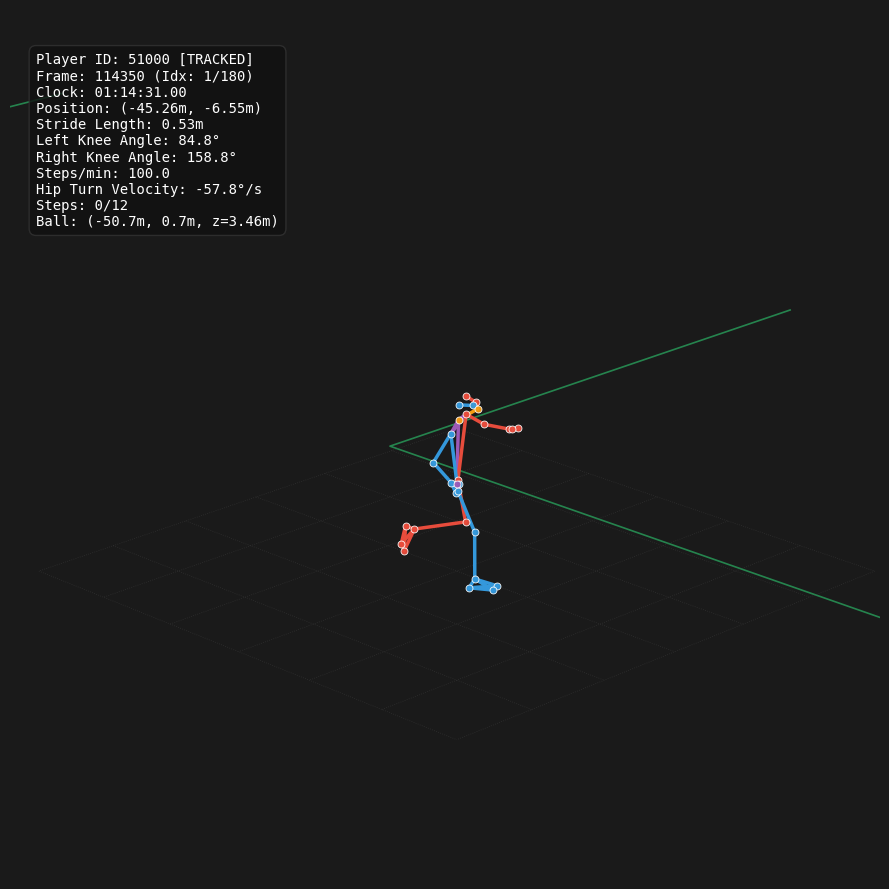

In [16]:
# Example of frames where the pose data is "confused"
anim = bpviz.animate_soccer_pose(
    path_to_jsonl='/content/raw/1996435.jsonl',
    start_frame=114350,
    num_frames=180,
    player_id=51000,
    no_axis=True,
)
HTML(anim.to_html5_video())